In [1]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
import os
from scipy.signal import welch
from specula.mmlib.utils import get_pupil_mask

2026-11-03 08:55:59,302 [INFO]: [specula]: Cupy import successfull. Installed version is: 13.3.0
2026-11-03 08:55:59,498 [INFO]: [specula]: Default device is GPU number 0


In [2]:
import matplotlib as mpl
from cycler import cycler

cmap = mpl.colormaps['hot'] # 1. Choose your colormap (e.g., 'hot', 'jet', 'turbo')
colors = cmap(np.linspace(0.0, 1.0, 7)) # 2. Extract a set of colors from it (e.g., 6 distinct colors across the map)
# plt.rcParams['axes.prop_cycle'] = cycler(color=colors) # 3. Apply it to the default line cycle
plt.rcParams['image.cmap'] = 'magma' # 4. Change the default colormap for images/scatter plots
plt.rcParams.update({
    "text.usetex": True, # Use LaTeX to write all text
    "font.family": "serif", # Use a serif font
    "font.serif": ["Computer Modern Roman"] # Specifically use the classic LaTeX font
})
plt.rcParams['image.origin'] = 'lower'

In [3]:
calib_dir = '/raid1/mmenessini/calibration/WFSW'
result_dir = '/raid1/mmenessini/results/WFSW'

In [ ]:
def rec_ron_cov(rec,frame,mask,RON,flux=None):
    if flux is None:
        flux = np.sum(frame)
    norm = np.mean(frame[mask.astype(bool)])
    norm_rec = rec / (norm / flux)
    rec_cov = norm_rec @ norm_rec.T
    return np.diag(rec_cov)/flux**2*RON

def rec_phot_cov(rec,frame,mask,sn,flux=None):
    if flux is None:
        flux = np.sum(frame)
    norm = np.mean(frame[mask.astype(bool)])
    phot_noise = np.diag(sn/ (norm / flux))
    rec_cov = rec @ phot_noise @ rec.T
    return np.diag(rec_cov)/flux

def rec_covariance(rec,frame,mask,sn,RON,flux=None):
    shot_cov = rec_phot_cov(rec,frame,mask,sn,flux)
    ron_cov = rec_ron_cov(rec,frame,mask,RON,flux)
    return shot_cov + ron_cov

In [58]:
frames_vis = fits.getdata(os.path.join(result_dir,'vis_frames.fits'))
frames_nir = fits.getdata(os.path.join(result_dir,'nir_frames.fits'))

def get_thrp_and_sn(frames):
    mframe = np.mean(frames,axis=0)
    flat_frame = mframe.flatten()
    mask = get_pupil_mask(npix=120,filepath=os.path.join(calib_dir,'pupils','pyr_pupdata_48x48.fits'))
    mflux = np.mean(mframe[mask.astype(bool)])
    # thrp = np.sum(mframe[mask.astype(bool)])/np.sum(mframe)
    hdu = fits.open(os.path.join(calib_dir,'pupils','pyr_pupdata_48x48.fits'))
    pup = hdu[1].data
    A = flat_frame[(pup[:,0][pup[:,0]>=0])]
    B = flat_frame[(pup[:,1][pup[:,1]>=0])]
    C = flat_frame[(pup[:,2][pup[:,2]>=0])]
    D = flat_frame[(pup[:,3][pup[:,3]>=0])]
    sx = (A+B-C-D)/mflux
    sy = (B+C-A-D)/mflux
    sn = np.hstack([sx,sy])
    return sn, mask

10.394949558238144 7.4733996035723695


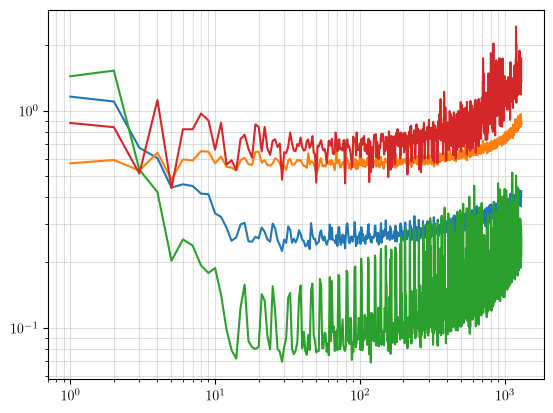

In [61]:
noisev = fits.getdata(os.path.join(result_dir,'20261103_120734','meas_vis.fits'))
noiser = fits.getdata(os.path.join(result_dir,'20261103_120734','meas_nir.fits'))
x = np.arange(1300)+1
rec0 = fits.getdata(os.path.join(calib_dir,'rec','pyr0.0_48x48_wvl900_bmc2k_vlt_1300modes_rec.fits'),1)
rec2 = fits.getdata(os.path.join(calib_dir,'rec','pyr2.0_48x48_wvl1300_bmc2k_vlt_1300modes_rec.fits'),1)

sn2,mask = get_thrp_and_sn(frames_vis)
sn0,_ = get_thrp_and_sn(frames_nir)

rec2_cov = rec_covariance(rec2,np.mean(frames_vis,axis=0),mask=mask,sn=sn2,RON=0.5)
rec0_cov = rec_covariance(rec0,np.mean(frames_nir,axis=0),mask=mask,sn=sn0,RON=0.5)

print(1/np.mean(rec2_cov/np.var(noisev,axis=0)),1/np.mean(rec0_cov/np.var(noiser,axis=0)))

plt.figure()
plt.loglog(x,np.std(noisev,axis=0))
plt.loglog(x,np.std(noiser,axis=0))
plt.loglog(x,rec2_cov*16)
plt.loglog(x,rec0_cov*16)
plt.grid(which='both',alpha=0.4)

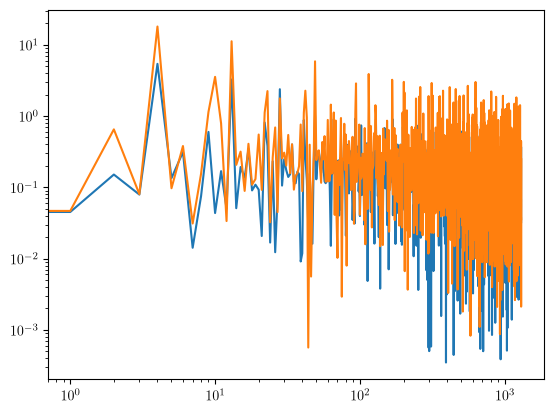

In [4]:
measv = fits.getdata(os.path.join(result_dir,'20261102_161603','meas_vis.fits'))
measr = fits.getdata(os.path.join(result_dir,'20261102_161603','meas_nir.fits'))
# modes = fits.getdata(os.path.join(result_dir,'20261102_130403','res.fits'))

plt.figure()
plt.loglog(abs(np.mean(measv,axis=0)))
plt.loglog(abs(np.mean(measr,axis=0)))
# plt.plot(modes[:,1299])

In [23]:
# noisev = fits.getdata(os.path.join(result_dir,'20261102_153912','noise_vis.fits'))
# noiser = fits.getdata(os.path.join(result_dir,'20261102_153912','noise_nir.fits'))
# sigv = fits.getdata(os.path.join(result_dir,'20261102_153912','sig_vis.fits'))
# sigr = fits.getdata(os.path.join(result_dir,'20261102_153912','sig_nir.fits'))
# x = np.arange(1300)+1

# plt.figure(figsize=(12,5))
# plt.subplot(1,2,1)
# plt.loglog(x,np.std(noisev,axis=0))
# plt.loglog(x,np.std(noiser,axis=0))
# plt.grid(which='both',alpha=0.4)
# plt.subplot(1,2,2)
# plt.loglog(x,np.std(sigr,axis=0))
# plt.loglog(x,np.std(sigv,axis=0))
# plt.grid(which='both',alpha=0.4)

(129,) (129, 1300)


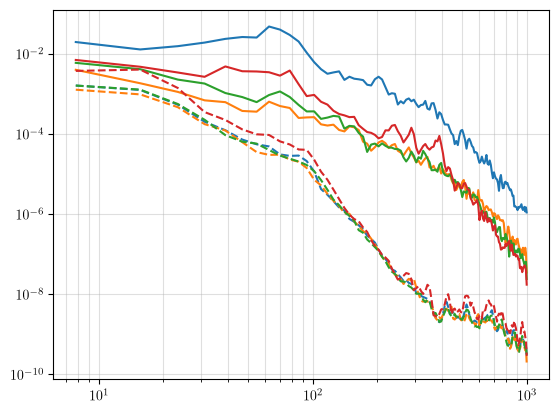

In [6]:
f,psdv = welch(measv,fs=500,axis=0)
f,psdr = welch(measr,fs=2000,axis=0)
print(f.shape,psdv.shape)

idxes = [1,10,100,1000]
plt.figure()
for idx in idxes:
    plt.loglog(f[1:],psdv[1:,idx])
for j,idx in enumerate(idxes):
    plt.loglog(f[1:],psdr[1:,idx],'--',c=f'C{j}')
plt.grid(which='both',alpha=0.4)

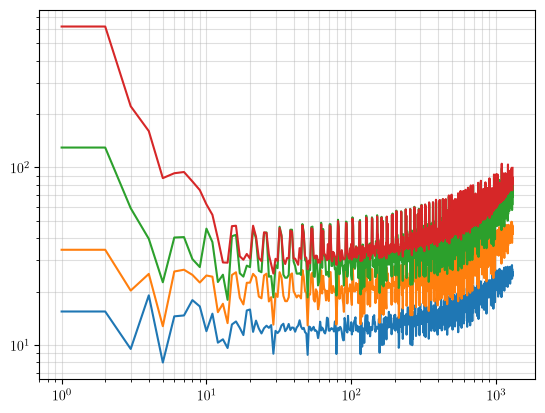

In [ ]:
rec0 = fits.getdata(os.path.join(calib_dir,'rec','pyr0.0_48x48_wvl1300_bmc2k_vlt_1300modes_rec.fits'),1)#*(900/1300)
rec05 = fits.getdata(os.path.join(calib_dir,'rec','pyr0.5_48x48_wvl1300_bmc2k_vlt_1300modes_rec.fits'),1)
rec1 = fits.getdata(os.path.join(calib_dir,'rec','pyr1.0_48x48_wvl1300_bmc2k_vlt_1300modes_rec.fits'),1)
rec2 = fits.getdata(os.path.join(calib_dir,'rec','pyr2.0_48x48_wvl1300_bmc2k_vlt_1300modes_rec.fits'),1)

plt.figure()
plt.loglog(np.arange(rec0.shape[0])+1,np.diag(rec0 @ rec0.T))
plt.loglog(np.arange(rec05.shape[0])+1,np.diag(rec05 @ rec05.T))
plt.loglog(np.arange(rec1.shape[0])+1,np.diag(rec1 @ rec1.T))
plt.loglog(np.arange(rec2.shape[0])+1,np.diag(rec2 @ rec2.T))
plt.grid(which='both',alpha=0.4)

In [ ]:
# wvl = 1300
# rec48x48 = fits.getdata(os.path.join(calib_dir,'rec',f'pyr0.0_48x48_wvl{wvl}_bmc2k_vlt_1300modes_rec.fits'),1)
# rec36x36 = fits.getdata(os.path.join(calib_dir,'rec',f'pyr0.0_36x36_wvl{wvl}_bmc2k_vlt_800modes_rec.fits'),1)
# rec24x24 = fits.getdata(os.path.join(calib_dir,'rec',f'pyr0.0_24x24_wvl{wvl}_bmc2k_vlt_300modes_rec.fits'),1)
# rec14x14 = fits.getdata(os.path.join(calib_dir,'rec',f'pyr0.0_14x14_wvl{wvl}_bmc2k_vlt_100modes_rec.fits'),1)
# rec10x10 = fits.getdata(os.path.join(calib_dir,'rec',f'pyr0.0_10x10_wvl{wvl}_bmc2k_vlt_54modes_rec.fits'),1)

# def plot_rec_cov(rec,nSubap:int=48):
#     plt.loglog(np.arange(rec.shape[0])+1,np.diag(rec @ rec.T)*(nSubap**2)/(48**2))

# plt.figure()
# plot_rec_cov(rec48x48,nSubap=48)
# plot_rec_cov(rec36x36,nSubap=36)
# plot_rec_cov(rec24x24,nSubap=24)
# plot_rec_cov(rec14x14,nSubap=14)
# plot_rec_cov(rec10x10,nSubap=10)
# plt.grid(which='both',alpha=0.4)